<a href="https://colab.research.google.com/github/IdreesMohamed/Post-Flood/blob/main/AmazonSalesDataSet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy scikit-learn tensorflow matplotlib

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.layers import Dropout, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

# 1. Load dataset
df = pd.read_csv("amazon.csv")

print("Dataset shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum())

# 2. Remove duplicate products
df = df.drop_duplicates(subset="product_id", keep="first").copy()

# 3. Clean numeric columns
def clean_number(series):
    return pd.to_numeric(
        series.astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("₹", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

for col in [
    "discounted_price", "actual_price",
    "discount_percentage", "rating", "rating_count"
]:
    df[col] = clean_number(df[col])

# 4. Remove rows without a valid target rating
df = df.dropna(subset=["rating"])
df = df[df["rating"].between(1, 5)].copy()

# 5. Fill missing product and review text
text_columns = [
    "product_name", "category", "about_product",
    "review_title", "review_content"
]

for col in text_columns:
    df[col] = df[col].fillna("")

# 6. Fill missing numerical product features
numeric_columns = [
    "discounted_price", "actual_price",
    "discount_percentage", "rating_count"
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# 7. Create a single text field
df["review_text"] = (
    df["product_name"] + " " +
    df["about_product"] + " " +
    df["review_title"] + " " +
    df["review_content"]
)

# 8. Basic text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["review_text"] = df["review_text"].apply(clean_text)

print("\nCleaned dataset shape:", df.shape)
print(df[["review_text", "rating"]].head())
print("\nMissing values after cleaning:",
      df.isnull().sum().sum())

Dataset shape: (1465, 16)
   product_id                                       product_name  \
0  B07JW9H4J1  Wayona Nylon Braided USB to Lightning Fast Cha...   
1  B098NS6PVG  Ambrane Unbreakable 60W / 3A Fast Charging 1.5...   
2  B096MSW6CT  Sounce Fast Phone Charging Cable & Data Sync U...   
3  B08HDJ86NZ  boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...   
4  B08CF3B7N1  Portronics Konnect L 1.2M Fast Charging 3A 8 P...   

                                            category discounted_price  \
0  Computers&Accessories|Accessories&Peripherals|...             ₹399   
1  Computers&Accessories|Accessories&Peripherals|...             ₹199   
2  Computers&Accessories|Accessories&Peripherals|...             ₹199   
3  Computers&Accessories|Accessories&Peripherals|...             ₹329   
4  Computers&Accessories|Accessories&Peripherals|...             ₹154   

  actual_price discount_percentage rating rating_count  \
0       ₹1,099                 64%    4.2       24,269   
1         

In [3]:
# Split the data before fitting the tokenizer or scaler
X_train, X_test, y_train, y_test = train_test_split(
    df,
    df["rating"].astype("float32"),
    test_size=0.20,
    random_state=42
)

# Tokenizer learns vocabulary from training text only
tokenizer = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train["review_text"])

max_words = 10000
max_len = 150

X_train_text = pad_sequences(
    tokenizer.texts_to_sequences(X_train["review_text"]),
    maxlen=max_len,
    padding="post",
    truncating="post"
)

X_test_text = pad_sequences(
    tokenizer.texts_to_sequences(X_test["review_text"]),
    maxlen=max_len,
    padding="post",
    truncating="post"
)

print("Training text shape:", X_train_text.shape)
print("Testing text shape:", X_test_text.shape)
print("Vocabulary size:",
      min(len(tokenizer.word_index) + 1, max_words))

Training text shape: (1080, 150)
Testing text shape: (270, 150)
Vocabulary size: 10000


In [4]:
# Extract the main product category
def get_category(value):
    parts = str(value).split("|")
    return parts[0].strip() if parts else "unknown"

X_train = X_train.copy()
X_test = X_test.copy()

X_train["main_category"] = X_train["category"].apply(get_category)
X_test["main_category"] = X_test["category"].apply(get_category)

# Numerical features
num_cols = [
    "discounted_price", "actual_price",
    "discount_percentage", "rating_count"
]

scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train[num_cols])
X_test_num = scaler.transform(X_test[num_cols])

# One-hot encode categories
X_train_cat = pd.get_dummies(
    X_train["main_category"], dtype="float32"
)

X_test_cat = pd.get_dummies(
    X_test["main_category"], dtype="float32"
)

# Ensure train and test have identical category columns
X_test_cat = X_test_cat.reindex(
    columns=X_train_cat.columns, fill_value=0
)

X_train_product = np.concatenate(
    [X_train_num, X_train_cat.to_numpy()], axis=1
).astype("float32")

X_test_product = np.concatenate(
    [X_test_num, X_test_cat.to_numpy()], axis=1
).astype("float32")

# Build a two-input LSTM model
text_input = Input(shape=(max_len,), name="review_input")

x = Embedding(
    input_dim=max_words,
    output_dim=64,
    mask_zero=True
)(text_input)

x = LSTM(32)(x)
x = Dropout(0.3)(x)

product_input = Input(
    shape=(X_train_product.shape[1],),
    name="product_input"
)

p = Dense(32, activation="relu")(product_input)

# Combine text and product features
combined = Concatenate()([x, p])
combined = Dense(32, activation="relu")(combined)
combined = Dropout(0.2)(combined)

output = Dense(1, activation="linear")(combined)

model = Model(
    inputs=[text_input, product_input],
    outputs=output
)

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

# Stop training if validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    [X_train_text, X_train_product],
    y_train.to_numpy(),
    validation_split=0.15,
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Predict test ratings
predictions = model.predict(
    [X_test_text, X_test_product]
).flatten()

# Restrict predictions to the valid rating range
predictions = np.clip(predictions, 1, 5)

# Evaluation metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\nMODEL EVALUATION")
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²  :", round(r2, 4))

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review_input        │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 64)   │    640,000 │ review_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 150)       │          0 │ review_input[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │     12,416 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_input       │ (None, 13)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        448 │ product_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 654,977 (2.50 MB)

 Trainable params: 654,977 (2.50 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - loss: 8.8186 - mae: 2.7449 - val_loss: 0.7360 - val_mae: 0.5260
Epoch 2/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.2929 - mae: 0.8311 - val_loss: 0.3008 - val_mae: 0.4552
Epoch 3/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.7729 - mae: 0.6659 - val_loss: 0.2491 - val_mae: 0.4122
Epoch 4/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6265 - mae: 0.6109 - val_loss: 0.2115 - val_mae: 0.3745
Epoch 5/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.5753 - mae: 0.6014 - val_loss: 0.2137 - val_mae: 0.3748
Epoch 6/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4943 - mae: 0.5655 - val_loss: 0.2031 - val_mae: 0.3619
Epoch 7/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.4959 - mae: 0.5608 - val_loss: 0.2045 - val_mae: 0.3625
Epoch 8/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.4413 - mae: 0.5183 - val_loss: 0.1834 - val_mae: 0.3351
Epoch 9/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.472

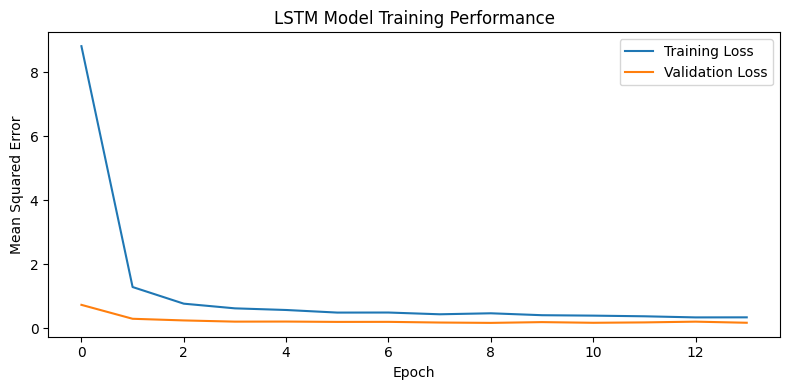

In [5]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("LSTM Model Training Performance")
plt.legend()
plt.tight_layout()
plt.show()

 Actual Rating  Predicted Rating  Absolute Error
           4.3              4.03            0.27
           4.1              3.93            0.17
           4.3              3.98            0.32
           3.9              3.92            0.02
           3.9              4.03            0.13
           3.5              4.05            0.55
           4.2              4.22            0.02
           4.4              3.88            0.52
           4.2              4.08            0.12
           4.0              4.05            0.05
           4.1              4.05            0.05
           4.2              3.81            0.39
           3.9              3.85            0.05
           4.1              4.06            0.04
           4.4              3.82            0.58


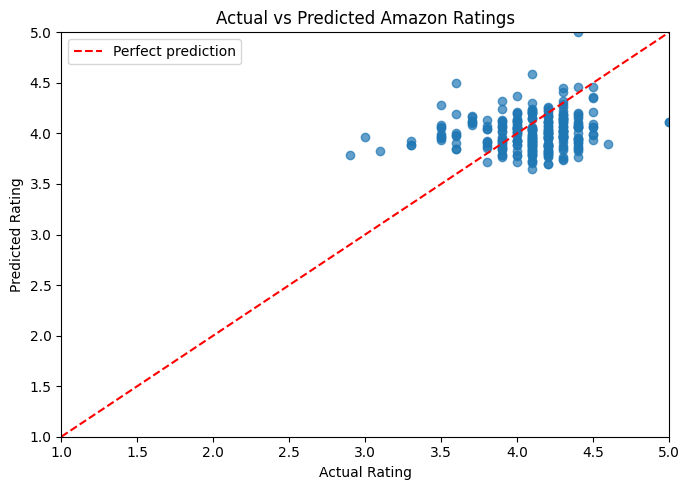

In [6]:
# Create comparison table
comparison = pd.DataFrame({
    "Actual Rating": y_test.to_numpy(),
    "Predicted Rating": predictions
})

comparison["Predicted Rating"] = (
    comparison["Predicted Rating"].round(2)
)

comparison["Absolute Error"] = (
    comparison["Actual Rating"] -
    comparison["Predicted Rating"]
).abs().round(2)

print(comparison.head(15).to_string(index=False))

# Visual comparison
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    predictions,
    alpha=0.7
)

plt.plot([1, 5], [1, 5], "r--", label="Perfect prediction")

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Amazon Ratings")
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
def predict_rating(
    review,
    product_name,
    category,
    about_product="",
    discounted_price=500,
    actual_price=1000,
    discount_percentage=50,
    rating_count=100
):
    # Prepare text
    text = clean_text(
        product_name + " " +
        about_product + " " +
        review
    )

    # Convert text into a padded sequence
    seq = tokenizer.texts_to_sequences([text])
    seq = pad_sequences(
        seq,
        maxlen=max_len,
        padding="post",
        truncating="post"
    )

    # Prepare numerical features
    num = pd.DataFrame([[
        discounted_price,
        actual_price,
        discount_percentage,
        rating_count
    ]], columns=num_cols)

    num_scaled = scaler.transform(num)

    # Encode the product category
    main_cat = get_category(category)

    cat_features = np.zeros(
        (1, len(X_train_cat.columns)),
        dtype="float32"
    )

    if main_cat in X_train_cat.columns:
        cat_features[0, list(X_train_cat.columns).index(main_cat)] = 1

    product_features = np.concatenate(
        [num_scaled, cat_features], axis=1
    ).astype("float32")

    # Predict the rating
    result = model.predict(
        [seq, product_features],
        verbose=0
    )[0][0]

    result = float(np.clip(result, 1, 5))

    print("Product:", product_name)
    print("Review:", review)
    print("Predicted rating:", round(result, 2), "/ 5 stars")

    return round(result, 2)


# Example 1: Positive review
predict_rating(
    review="Excellent product, great quality and fast charging.",
    product_name="USB Charging Cable",
    category="Electronics|Accessories",
    about_product="Fast charging USB cable",
    discounted_price=299,
    actual_price=599,
    discount_percentage=50,
    rating_count=500
)

# Example 2: Negative review
predict_rating(
    review="Poor quality, stopped working after two days.",
    product_name="USB Charging Cable",
    category="Electronics|Accessories",
    about_product="Fast charging USB cable",
    discounted_price=299,
    actual_price=599,
    discount_percentage=50,
    rating_count=500
)

Product: USB Charging Cable
Review: Excellent product, great quality and fast charging.
Predicted rating: 3.61 / 5 stars
Product: USB Charging Cable
Review: Poor quality, stopped working after two days.
Predicted rating: 3.31 / 5 stars


3.31

Confusion Matrix:
 [[  0   0   0   0   0]
 [  0   0   0   0   0]
 [  0   0   0   6   0]
 [  0   0   0 249   2]
 [  0   0   0  13   0]]


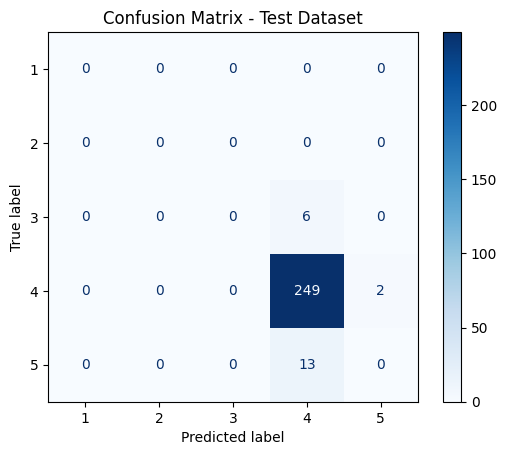

              precision    recall  f1-score   support

           1       0.00      0.00      0.00         0
           2       0.00      0.00      0.00         0
           3       0.00      0.00      0.00         6
           4       0.93      0.99      0.96       251
           5       0.00      0.00      0.00        13

    accuracy                           0.92       270
   macro avg       0.19      0.20      0.19       270
weighted avg       0.86      0.92      0.89       270



In [8]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import numpy as np

# Convert actual ratings into integer classes
actual_class = np.clip(
    np.floor(np.asarray(y_test) + 0.5), 1, 5
).astype(int)

# Convert predicted ratings into integer classes
predicted_class = np.clip(
    np.floor(predictions + 0.5), 1, 5
).astype(int)

# Create confusion matrix
labels = [1, 2, 3, 4, 5]

cm = confusion_matrix(
    actual_class,
    predicted_class,
    labels=labels
)

print("Confusion Matrix:\n", cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Test Dataset")
plt.show()

print(classification_report(
    actual_class,
    predicted_class,
    labels=labels,
    zero_division=0
))

Whole dataset confusion matrix:
 [[   0    0    0    0    0]
 [   0    0    0    2    0]
 [   0    0    3   36    0]
 [   0    0    0 1204    9]
 [   0    0    0   94    2]]


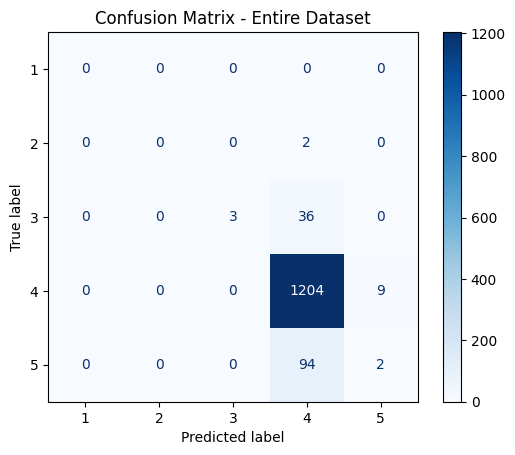

In [9]:
# Encode reviews from every row
all_text = pad_sequences(
    tokenizer.texts_to_sequences(df["review_text"]),
    maxlen=max_len,
    padding="post",
    truncating="post"
)

# Prepare numerical features
all_num = scaler.transform(df[num_cols])

# Encode categories using the same columns as training
all_cat = pd.get_dummies(
    df["main_category"] if "main_category" in df.columns
    else df["category"].apply(get_category),
    dtype="float32"
)

all_cat = all_cat.reindex(
    columns=X_train_cat.columns,
    fill_value=0
)

all_product = np.concatenate(
    [all_num, all_cat.to_numpy()],
    axis=1
).astype("float32")

# Predict all rows
all_predictions = model.predict(
    [all_text, all_product],
    verbose=0
).flatten()

all_predictions = np.clip(all_predictions, 1, 5)

# Convert continuous ratings to classes
all_actual_class = np.clip(
    np.floor(df["rating"].to_numpy() + 0.5), 1, 5
).astype(int)

all_predicted_class = np.clip(
    np.floor(all_predictions + 0.5), 1, 5
).astype(int)

cm_all = confusion_matrix(
    all_actual_class,
    all_predicted_class,
    labels=[1, 2, 3, 4, 5]
)

print("Whole dataset confusion matrix:\n", cm_all)

ConfusionMatrixDisplay(
    confusion_matrix=cm_all,
    display_labels=[1, 2, 3, 4, 5]
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Entire Dataset")
plt.show()

In [13]:

import numpy as np
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, confusion_matrix, classification_report
)

# Find existing variables in the notebook
v = globals()

# Find actual test ratings
target_names = ["y_test", "Y_test", "y_test_rating", "actual_ratings"]
target_name = next((n for n in target_names if n in v), None)

if target_name is None:
    raise ValueError(
        "Test ratings not found. Run your dataset split and model training cells first."
    )

actual = np.asarray(v[target_name]).reshape(-1)

# Find existing predictions, or generate them from the model
pred_names = ["y_pred", "predictions", "y_pred_test", "predicted_ratings"]
pred_name = next((n for n in pred_names if n in v), None)

if pred_name is not None:
    predicted = np.asarray(v[pred_name]).reshape(-1)
else:
    model_obj = v.get("model")
    if model_obj is None:
        raise ValueError("Trained model variable 'model' was not found.")

    # Detect common model input variable names
    text_names = ["X_text_test", "X_test_text", "X_test_pad",
                  "X_test_seq", "test_padded"]
    feature_names = ["X_features_test", "X_test_features",
                     "X_test_scaled", "X_test_num"]

    text_var = next((n for n in text_names if n in v), None)
    feature_var = next((n for n in feature_names if n in v), None)

    if text_var and feature_var:
        output = model_obj.predict(
            [v[text_var], v[feature_var]], verbose=0
        )
    elif "X_test" in v:
        output = model_obj.predict(v["X_test"], verbose=0)
    else:
        raise ValueError(
            "Test input variables not found. Check your notebook's test-data names."
        )

    predicted = np.asarray(output).reshape(-1)

# Check that actual and predicted ratings match in length
if len(actual) != len(predicted):
    raise ValueError(
        f"Length mismatch: {len(actual)} actual ratings, "
        f"{len(predicted)} predictions."
    )

# Regression metrics
mae = mean_absolute_error(actual, predicted)
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)
r2 = r2_score(actual, predicted)

print("===== RATING PREDICTION RESULTS =====")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

# Classification-style metrics after rounding to 1-5 stars
actual_class = np.clip(np.rint(actual), 1, 5).astype(int)
predicted_class = np.clip(np.rint(predicted), 1, 5).astype(int)

accuracy = accuracy_score(actual_class, predicted_class)
print(f"Rounded Rating Accuracy: {accuracy * 100:.2f}%")

print("\n===== CONFUSION MATRIX =====")
print(confusion_matrix(actual_class, predicted_class,
                       labels=[1, 2, 3, 4, 5]))

print("\n===== PRECISION / RECALL / F1 =====")
print(classification_report(
    actual_class, predicted_class,
    labels=[1, 2, 3, 4, 5],
    zero_division=0
))


===== RATING PREDICTION RESULTS =====
MAE  : 0.2580
MSE  : 0.1023
RMSE : 0.3198
R2   : -0.2694
Rounded Rating Accuracy: 95.93%

===== CONFUSION MATRIX =====
[[  0   0   0   0   0]
 [  0   0   0   0   0]
 [  0   0   0   6   0]
 [  0   0   0 259   2]
 [  0   0   0   3   0]]

===== PRECISION / RECALL / F1 =====
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         0
           2       0.00      0.00      0.00         0
           3       0.00      0.00      0.00         6
           4       0.97      0.99      0.98       261
           5       0.00      0.00      0.00         3

    accuracy                           0.96       270
   macro avg       0.19      0.20      0.20       270
weighted avg       0.93      0.96      0.95       270

